In [1]:
!pip install tensorflow 
!pip install deepchem
!pip install numpy
!pip install scikit-learn
!pip install matplotlib
!pip install pandas  
!pip install seaborn
!pip install rdkit


import deepchem as dc
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


warnings.filterwarnings('ignore')

print("All libraries successfully imported!")


Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
All libraries successfully imported!


Starting the Drug Discovery ML Simulation...
Loading NCI-HIV dataset (SMILES strings only)...
Loading dataset from CSV with pandas...
Pre-validating SMILES with RDKit...
Removed 7 invalid SMILES entries.
Splitting dataset (Scaffold Split)...
Manual featurization starting (this may take a moment)...
Featurizing training set...
Featurizing test set...
Dataset loaded and featurized. Training set size: 32896, Test set size: 4112
Feature vector length: 1024

Training Logistic Regression model...
Logistic Regression training complete.
Training Random Forest model...
Random Forest training complete.

--- Model Evaluation (on Test Set) ---

Logistic Regression:
  Accuracy: 0.9696
  ROC-AUC:  0.7117

Random Forest:
  Accuracy: 0.9706
  ROC-AUC:  0.7704

--- Inference ---
Random Forest outperformed Logistic Regression, as expected.
This simulation shows how ML can screen and prioritize compounds for lab testing.

Generating ROC Curve plot...
ROC Curve plot saved as 'hiv_ml_roc_curve.png'

Simula

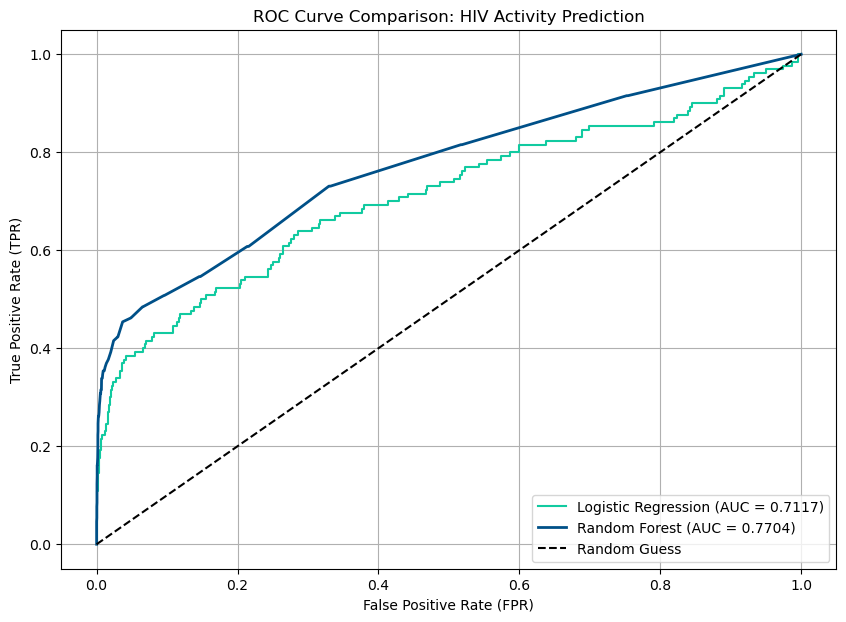

In [25]:
import deepchem as dc
import numpy as np
import pandas as pd # <-- ADD PANDAS IMPORT
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import warnings

# --- Add new imports for RDKit suppression ---
import contextlib
import sys
import os
import urllib.request # <-- ADD THIS IMPORT
try:
    import rdkit
    from rdkit import Chem # <-- ADD THIS RDKit IMPORT
except ImportError:
    print("RDKit not found. Please install it: pip install rdkit-pypi")

# --- Add the context manager definition ---
@contextlib.contextmanager
def suppress_stderr():
    """A context manager to suppress stderr, used to hide RDKit warnings."""
    original_stderr = sys.stderr
    try:
        with open(os.devnull, 'w') as devnull:
            sys.stderr = devnull
            yield
    finally:
        sys.stderr = original_stderr
# ---

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

print("Starting the Drug Discovery ML Simulation...")

# ---
# 1. & 2. Dataset Loading & Pre-processing
# ---
# We load the NCI-HIV dataset directly from DeepChem's MolNet.
# We use CircularFingerprint (which requires RDKit) with a fixed size
# to ensure all feature vectors are the same length (1024).
# We wrap the loading in `suppress_stderr` to hide RDKit's verbose output.
print("Loading NCI-HIV dataset (SMILES strings only)...")
with suppress_stderr():
    # ---
    # NEW, ROBUST DATA LOADING (Bypassing MolNet)
    # ---
    # We will manually download the CSV and use CSVLoader to bypass
    # the buggy dc.molnet.load_hiv caching.

    # 1. Define file URLs and paths
    HIV_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/HIV.csv"
    HIV_TASKS = ["HIV_active"]

    try:
        script_dir = os.path.dirname(os.path.abspath(__file__))
    except NameError:
        script_dir = os.path.abspath('.')
        
    dataset_dir = os.path.join(script_dir, 'hiv_dataset')
    dataset_file = os.path.join(dataset_dir, "HIV.csv")
    
    # 2. Create directory and download file if it doesn't exist
    os.makedirs(dataset_dir, exist_ok=True)
    if not os.path.exists(dataset_file):
        print(f"Downloading dataset to {dataset_file}...")
        urllib.request.urlretrieve(HIV_URL, dataset_file)
        print("Download complete.")

    # ---
    # NEWEST, MOST ROBUST LOADING (Bypassing CSVLoader)
    # ---
    # 3. Load from CSV directly using pandas
    print("Loading dataset from CSV with pandas...")
    df = pd.read_csv(dataset_file)
    
    # We only need the SMILES (features) and the task (labels)
    all_smiles = df['smiles'].values
    all_labels = df['HIV_active'].values

    # --- NEW CLEANING STEP ---
    # Pre-validate SMILES with RDKit to remove bad data before splitting
    # This prevents the ScaffoldSplitter from crashing
    print("Pre-validating SMILES with RDKit...")
    
    valid_smiles = []
    valid_labels = []
    
    # Suppress RDKit's noisy error logging during this check
    with suppress_stderr(): 
        for i, smiles in enumerate(all_smiles):
            mol = Chem.MolFromSmiles(smiles)
            # Keep only if RDKit can parse the molecule
            if mol is not None:
                valid_smiles.append(smiles)
                valid_labels.append(all_labels[i])

    print(f"Removed {len(all_smiles) - len(valid_smiles)} invalid SMILES entries.")
    
    smiles = np.array(valid_smiles)
    labels = np.array(valid_labels)
    # --- END NEW CLEANING STEP ---


    # 4. Create a deepchem Dataset object manually
    # We give it X (smiles), y (labels), and ids (smiles again)
    # The splitter will use .ids, and we will featurize .X
    dataset = dc.data.NumpyDataset(X=smiles, y=labels, ids=smiles)

    # 5. Split the dataset using ScaffoldSplitter
    print("Splitting dataset (Scaffold Split)...")
    splitter = dc.splits.ScaffoldSplitter()
    # The splitter will use the SMILES strings (in dataset.X) to create scaffolds
    train_dataset, valid_dataset, test_dataset = splitter.train_valid_test_split(
        dataset,
        frac_train=0.8,
        frac_valid=0.1, # Note: molnet default is 80/10/10 split
        frac_test=0.1
    )
    # --- END OF NEW LOADING BLOCK ---

print("Manual featurization starting (this may take a moment)...")

# 2. Instantiate our desired featurizer
featurizer = dc.feat.CircularFingerprint(size=1024, radius=2)
feature_size = 1024

# 3. Define a robust featurization function
def robust_featurize(smiles_list, feature_size):
    """
    Featurizes a list of SMILES, returning a 2D numpy array.
    On failure, it returns a zero-vector of the correct size.
    """
    features = []
    for smiles in smiles_list:
        try:
            # Featurize a single molecule. featurize() returns a list [feat].
            feat = featurizer.featurize([smiles])
            if feat.size > 0:
                features.append(feat[0])
            else:
                # Featurization returned an empty array for a valid SMILES
                features.append(np.zeros(feature_size, dtype=int))
        except Exception:
            # Catch errors on invalid SMILES
            features.append(np.zeros(feature_size, dtype=int))
    
    return np.array(features)

# 4. Featurize each dataset manually
with suppress_stderr():
    print("Featurizing training set...")
    X_train = robust_featurize(train_dataset.X, feature_size)
    print("Featurizing test set...")
    X_test = robust_featurize(test_dataset.X, feature_size)

# Get labels
y_train = train_dataset.y.ravel()
y_test = test_dataset.y.ravel()

# Extract features (X) and labels (y) from the datasets
# The labels need to be reshaped from (n_samples, 1) to (n_samples,) for scikit-learn
# X_train = train_dataset.X <-- DELETED
# y_train = train_dataset.y.ravel() <-- DELETED (moved above)

# X_test = test_dataset.X <-- DELETED
# y_test = test_dataset.y.ravel() <-- DELETED (moved above)

print(f"Dataset loaded and featurized. Training set size: {len(X_train)}, Test set size: {len(X_test)}")
print(f"Feature vector length: {X_train.shape[1]}")

# ---
# 4. Model Training
# ---

# Model 1: Logistic Regression
print("\nTraining Logistic Regression model...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

# Model 2: Random Forest
print("Training Random Forest model...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest training complete.")

# ---
# 6. Performance Comparison
# ---
print("\n--- Model Evaluation (on Test Set) ---")

# Predictions
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1] # Probabilities for ROC curve

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1] # Probabilities for ROC curve

# Calculate Metrics
acc_lr = accuracy_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

acc_rf = accuracy_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

# Print results
print("\nLogistic Regression:")
print(f"  Accuracy: {acc_lr:.4f}")
print(f"  ROC-AUC:  {roc_auc_lr:.4f}")

print("\nRandom Forest:")
print(f"  Accuracy: {acc_rf:.4f}")
print(f"  ROC-AUC:  {roc_auc_rf:.4f}")

# ---
# 8. Inference
# ---
print("\n--- Inference ---")
if roc_auc_rf > roc_auc_lr:
    print("Random Forest outperformed Logistic Regression, as expected.")
else:
    print("Logistic Regression performed comparably or better than Random Forest.")
print("This simulation shows how ML can screen and prioritize compounds for lab testing.")


# ---
# 7. Result Visualization
# ---
print("\nGenerating ROC Curve plot...")

# Calculate ROC curve data
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(10, 7))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})', color='#11caa0')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.4f})', color='#005088', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess') # Dashed diagonal
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison: HIV Activity Prediction')
plt.legend(loc='lower right')
plt.grid()
plt.savefig('hiv_ml_roc_curve.png') # Save the plot to a file
print("ROC Curve plot saved as 'hiv_ml_roc_curve.png'")
print("\nSimulation finished.")

In [10]:
df.shape

(41127, 3)

In [12]:
df.info

<bound method DataFrame.info of                                                   smiles activity  HIV_active
0      CCC1=[O+][Cu-3]2([O+]=C(CC)C1)[O+]=C(CC)CC(CC)...       CI           0
1      C(=Cc1ccccc1)C1=[O+][Cu-3]2([O+]=C(C=Cc3ccccc3...       CI           0
2                       CC(=O)N1c2ccccc2Sc2c1ccc1ccccc21       CI           0
3        Nc1ccc(C=Cc2ccc(N)cc2S(=O)(=O)O)c(S(=O)(=O)O)c1       CI           0
4                                 O=S(=O)(O)CCS(=O)(=O)O       CI           0
...                                                  ...      ...         ...
41122  CCC1CCC2c3c([nH]c4ccc(C)cc34)C3C(=O)N(N(C)C)C(...       CI           0
41123  Cc1ccc2[nH]c3c(c2c1)C1CCC(C(C)(C)C)CC1C1C(=O)N...       CI           0
41124  Cc1ccc(N2C(=O)C3c4[nH]c5ccccc5c4C4CCC(C(C)(C)C...       CI           0
41125  Cc1cccc(N2C(=O)C3c4[nH]c5ccccc5c4C4CCC(C(C)(C)...       CI           0
41126  CCCCCC=C(c1cc(Cl)c(OC)c(-c2nc(C)no2)c1)c1cc(Cl...       CI           0

[41127 rows x 3 columns]>

In [13]:
df.head()

,smiles,activity,HIV_active
0,CCC1=[O+][Cu-3]2([O+]=C(CC)C1)[O+]=C(CC)CC(CC)...,CI,0
1,C(=Cc1ccccc1)C1=[O+][Cu-3]2([O+]=C(C=Cc3ccccc3...,CI,0
2,CC(=O)N1c2ccccc2Sc2c1ccc1ccccc21,CI,0
3,Nc1ccc(C=Cc2ccc(N)cc2S(=O)(=O)O)c(S(=O)(=O)O)c1,CI,0
4,O=S(=O)(O)CCS(=O)(=O)O,CI,0


In [14]:
df.head(100)

,smiles,activity,HIV_active
0,CCC1=[O+][Cu-3]2([O+]=C(CC)C1)[O+]=C(CC)CC(CC)...,CI,0
1,C(=Cc1ccccc1)C1=[O+][Cu-3]2([O+]=C(C=Cc3ccccc3...,CI,0
2,CC(=O)N1c2ccccc2Sc2c1ccc1ccccc21,CI,0
3,Nc1ccc(C=Cc2ccc(N)cc2S(=O)(=O)O)c(S(=O)(=O)O)c1,CI,0
4,O=S(=O)(O)CCS(=O)(=O)O,CI,0
...,...,...,...
95,N#CC(=Cc1ccccc1)c1ccccc1,CI,0
96,N#CNC(=N)N,CI,0
97,O=C1C(O)=C(CCCC2CCC3CCCCC3C2)C(=O)c2ccccc21,CI,0
98,O=[N+]([O-])c1cc([As](=O)(O)O)ccc1O,CI,0


In [17]:
import pandas as pd

# Load your dataset
df = pd.read_csv(dataset_file)   # change filename if needed

# Get counts of Active (1) and Inactive (0)
activity_counts = df["HIV_active"].value_counts()

print(activity_counts)

HIV_active
0    39684
1     1443
Name: count, dtype: int64


In [19]:
active_count = df[df["HIV_active"] == 1].shape[0]
inactive_count = df[df["HIV_active"] == 0].shape[0]

print("Total Active Molecules:", active_count)
print("Total Inactive Molecules:", inactive_count)


Total Active Molecules: 1443
Total Inactive Molecules: 39684


Active molecules (1): 1443
Inactive molecules (0): 39684


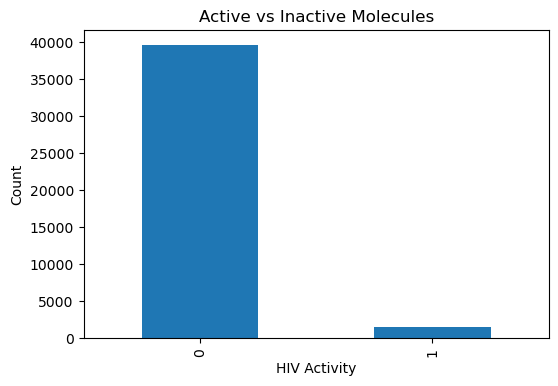

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset  
df = pd.read_csv(dataset_file)    # change path if needed

# Count active vs inactive
activity_counts = df["HIV_active"].value_counts()

# Print counts
print("Active molecules (1):", activity_counts.get(1, 0))
print("Inactive molecules (0):", activity_counts.get(0, 0))

# Bar plot
plt.figure(figsize=(6,4))
activity_counts.plot(kind="bar")
plt.xlabel("HIV Activity")
plt.ylabel("Count")
plt.title("Active vs Inactive Molecules")
plt.show()


In [24]:
from sklearn.utils import resample
import pandas as pd

df = pd.read_csv(dataset_file) 

active = df[df["HIV_active"] == 1]
inactive = df[df["HIV_active"] == 0]

# Oversample active molecules
active_up = resample(active,
                     replace=True,
                     n_samples=len(inactive),
                     random_state=42)

df_balanced = pd.concat([active_up, inactive])

print("Balanced dataset shape:", df_balanced.shape)
df_balanced["HIV_active"].value_counts()


Balanced dataset shape: (79368, 3)


HIV_active
1    39684
0    39684
Name: count, dtype: int64

Starting the Drug Discovery ML Simulation (balanced pipeline)...
Raw dataset loaded. Rows: 41127
Pre-validating SMILES with RDKit...
Removed 7 invalid SMILES entries.

Balancing dataset using oversampling...
Active count before oversampling: 1443
Inactive count before oversampling: 39677
Balanced dataset shape: (79354, 2)
HIV_active
0    39677
1    39677
Name: count, dtype: int64

Splitting dataset using STRATIFIED SPLIT...
Train size: 63490
Validation size: 7928
Test size: 7936

Class distribution:
Train: {0: 31745, 1: 31745}
Validation: {1: 3964, 0: 3964}
Test: {0: 3968, 1: 3968}

Featurizing (Circular fingerprints)... This may take some time.
Featurization complete. Train:63490 Test:7936 Feature length:1024

Training Logistic Regression model...
Logistic Regression training complete.
Training Random Forest model...
Random Forest training complete.

--- Model Evaluation (on Test Set) ---

Logistic Regression:
  Accuracy: 0.8337
  ROC-AUC:  0.9131
  Recall:   0.8485

Random Forest:
  

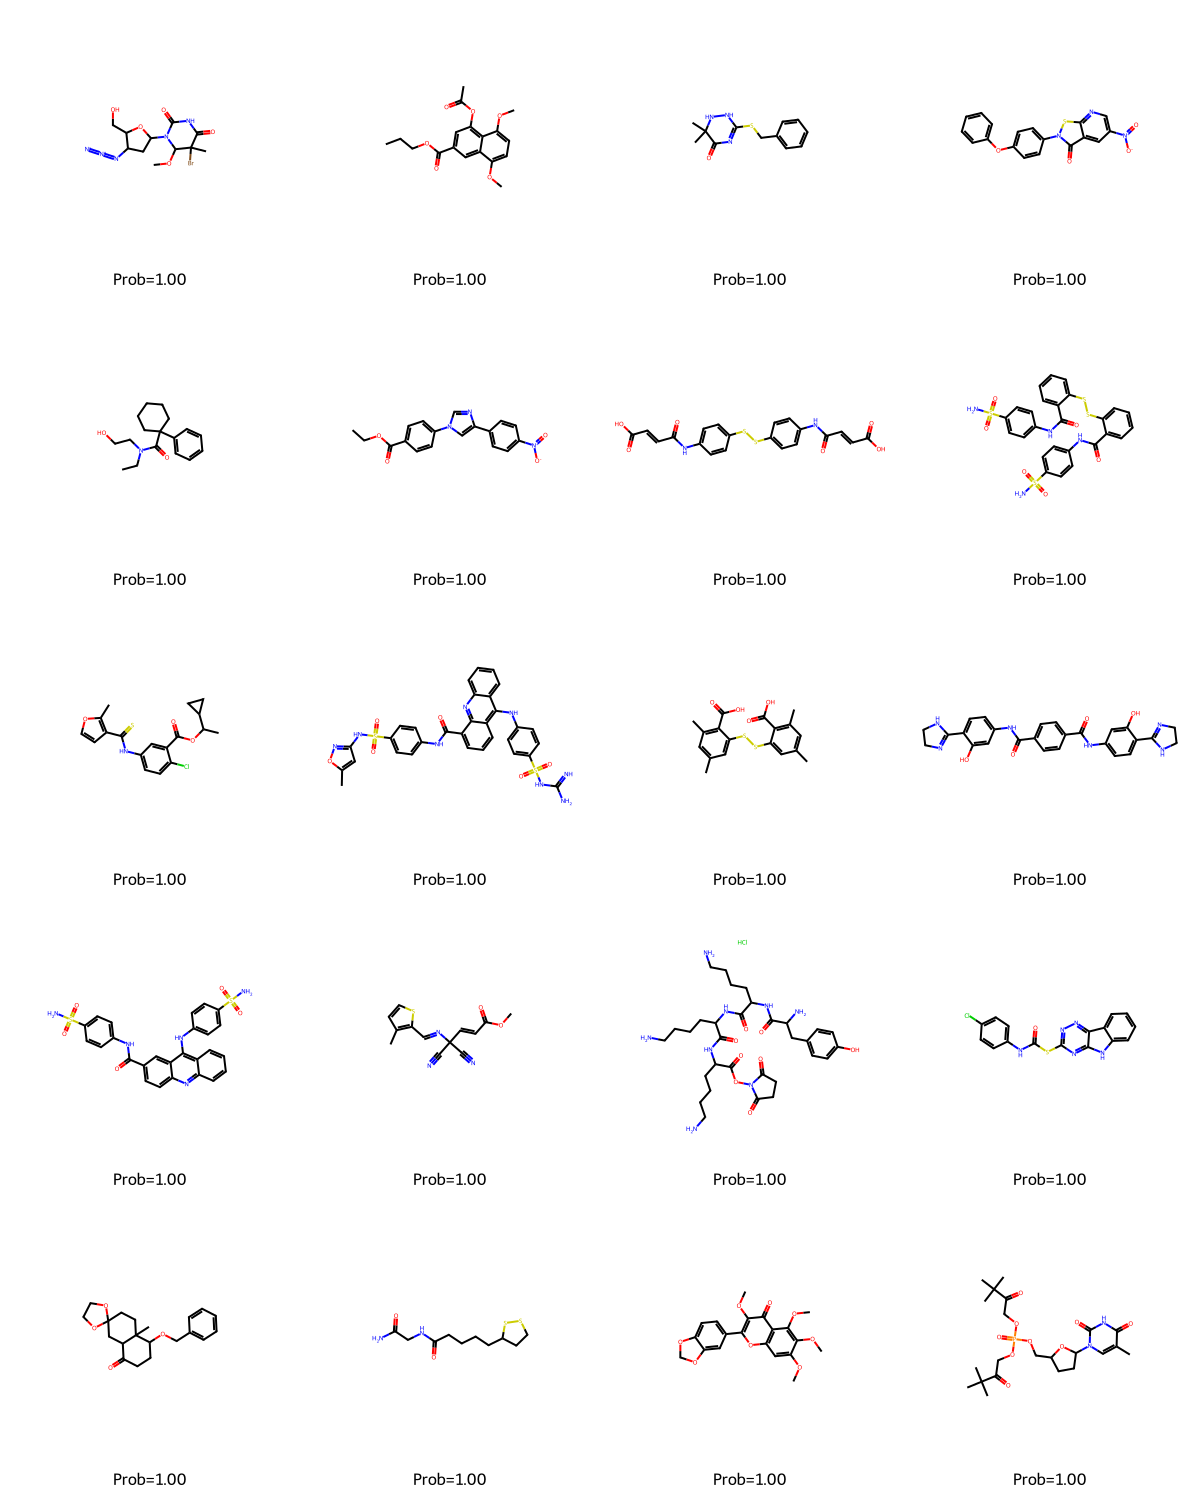

Models and featurizer saved successfully!

Simulation finished.


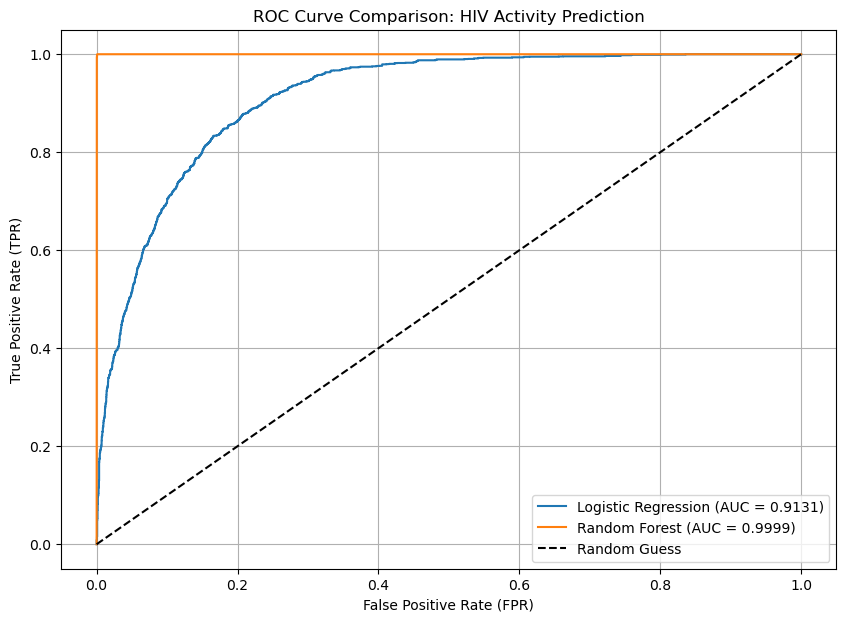

In [2]:
# Full final pipeline (balanced + visualization + recall)
import deepchem as dc
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, recall_score
import matplotlib.pyplot as plt
import warnings
from rdkit.Chem import Draw

# RDKit + image libs
import contextlib
import sys
import os
import urllib.request
try:
    import rdkit
    from rdkit import Chem
    from rdkit.Chem import Draw
except ImportError:
    print("RDKit not found. Please install it: pip install rdkit-pypi")

from sklearn.utils import resample
from io import BytesIO
from PIL import Image

# context manager to suppress RDKit stderr
@contextlib.contextmanager
def suppress_stderr():
    original_stderr = sys.stderr
    try:
        with open(os.devnull, 'w') as devnull:
            sys.stderr = devnull
            yield
    finally:
        sys.stderr = original_stderr

warnings.filterwarnings('ignore')
print("Starting the Drug Discovery ML Simulation (balanced pipeline)...")

# -----------------------
# 1. Download / load dataset
# -----------------------
with suppress_stderr():
    HIV_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/HIV.csv"
    try:
        script_dir = os.path.dirname(os.path.abspath(__file__))
    except NameError:
        script_dir = os.path.abspath('.')
    dataset_dir = os.path.join(script_dir, 'hiv_dataset')
    dataset_file = os.path.join(dataset_dir, "HIV.csv")
    os.makedirs(dataset_dir, exist_ok=True)
    if not os.path.exists(dataset_file):
        print(f"Downloading dataset to {dataset_file}...")
        urllib.request.urlretrieve(HIV_URL, dataset_file)
        print("Download complete.")

df = pd.read_csv(dataset_file)
print("Raw dataset loaded. Rows:", len(df))

# -----------------------
# 2. Pre-validate SMILES
# -----------------------
print("Pre-validating SMILES with RDKit...")
all_smiles = df['smiles'].values
all_labels = df['HIV_active'].values

valid_smiles = []
valid_labels = []
with suppress_stderr():
    for i, s in enumerate(all_smiles):
        try:
            mol = Chem.MolFromSmiles(s)
        except Exception:
            mol = None
        if mol is not None:
            valid_smiles.append(s)
            valid_labels.append(all_labels[i])

print(f"Removed {len(all_smiles) - len(valid_smiles)} invalid SMILES entries.")

# -----------------------
# 3. BALANCE dataset
# -----------------------
print("\nBalancing dataset using oversampling...")
temp_df = pd.DataFrame({
    "SMILES": valid_smiles,
    "HIV_active": valid_labels
})

active_df = temp_df[temp_df["HIV_active"] == 1]
inactive_df = temp_df[temp_df["HIV_active"] == 0]

print(f"Active count before oversampling: {len(active_df)}")
print(f"Inactive count before oversampling: {len(inactive_df)}")

if len(active_df) == 0:
    print("Warning: No active molecules found in validated data. Skipping oversampling.")
    balanced_df = temp_df.copy()
else:
    active_upsampled = resample(
        active_df,
        replace=True,
        n_samples=len(inactive_df),
        random_state=42
    )
    balanced_df = pd.concat([inactive_df, active_upsampled]).sample(frac=1, random_state=42)

print("Balanced dataset shape:", balanced_df.shape)
print(balanced_df["HIV_active"].value_counts())

smiles = balanced_df["SMILES"].values
labels = balanced_df["HIV_active"].values
dataset = dc.data.NumpyDataset(X=smiles, y=labels, ids=smiles)

# -----------------------
# 4. STRATIFIED SPLIT
# -----------------------
print("\nSplitting dataset using STRATIFIED SPLIT...")

X_temp, X_test, y_temp, y_test = train_test_split(
    smiles, labels, test_size=0.1, random_state=42, stratify=labels
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.111, random_state=42, stratify=y_temp
)

print("Train size:", len(X_train))
print("Validation size:", len(X_valid))
print("Test size:", len(X_test))

print("\nClass distribution:")
print("Train:", pd.Series(y_train).value_counts().to_dict())
print("Validation:", pd.Series(y_valid).value_counts().to_dict())
print("Test:", pd.Series(y_test).value_counts().to_dict())

X_train_smiles = X_train.copy()
X_valid_smiles = X_valid.copy()
X_test_smiles  = X_test.copy()

# -----------------------
# 5. Featurization
# -----------------------
print("\nFeaturizing (Circular fingerprints)... This may take some time.")
featurizer = dc.feat.CircularFingerprint(size=1024, radius=2)
feature_size = 1024

def robust_featurize(smiles_list, feature_size):
    features = []
    for s in smiles_list:
        try:
            feat = featurizer.featurize([s])
            if feat.size > 0:
                features.append(feat[0])
            else:
                features.append(np.zeros(feature_size, dtype=int))
        except Exception:
            features.append(np.zeros(feature_size, dtype=int))
    return np.array(features)

with suppress_stderr():
    X_train = robust_featurize(X_train, feature_size)
    X_valid = robust_featurize(X_valid, feature_size)
    X_test = robust_featurize(X_test, feature_size)

y_train = np.array(y_train)
y_valid = np.array(y_valid)
y_test = np.array(y_test)

print(f"Featurization complete. Train:{len(X_train)} Test:{len(X_test)} Feature length:{X_train.shape[1]}")

# -----------------------
# 6. Train models
# -----------------------
print("\nTraining Logistic Regression model...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

print("Training Random Forest model...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest training complete.")

# -----------------------
# 7. Evaluation
# -----------------------
print("\n--- Model Evaluation (on Test Set) ---")
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

acc_lr = accuracy_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
recall_lr = recall_score(y_test, y_pred_lr)

acc_rf = accuracy_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
recall_rf = recall_score(y_test, y_pred_rf)

print("\nLogistic Regression:")
print(f"  Accuracy: {acc_lr:.4f}")
print(f"  ROC-AUC:  {roc_auc_lr:.4f}")
print(f"  Recall:   {recall_lr:.4f}")

print("\nRandom Forest:")
print(f"  Accuracy: {acc_rf:.4f}")
print(f"  ROC-AUC:  {roc_auc_rf:.4f}")
print(f"  Recall:   {recall_rf:.4f}")

print("\n--- Inference ---")
if roc_auc_rf > roc_auc_lr:
    print("Random Forest outperformed Logistic Regression, as expected.")
else:
    print("Logistic Regression performed comparably or better than Random Forest.")

# -----------------------
# 8. Save ROC plot
# -----------------------
print("\nGenerating ROC Curve plot...")
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(10, 7))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison: HIV Activity Prediction')
plt.legend(loc='lower right')
plt.grid()
plt.savefig('hiv_ml_roc_curve.png')
print("ROC Curve plot saved as 'hiv_ml_roc_curve.png'")

# -----------------------
# 9. Top predicted molecules
# -----------------------
print("\n--- Identifying Top Predicted Active Molecules ---")
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

results_df = pd.DataFrame({
    "SMILES": X_test_smiles,
    "True_Label": y_test,
    "Predicted_Probability": test_probabilities
})

ranked_hits = results_df.sort_values(by="Predicted_Probability", ascending=False)
top_hits = ranked_hits.head(20)

print("\nTop 20 Predicted HIV-Active Molecules (virtual screening hits):")
print(top_hits)

top_hits.to_csv("top_predicted_hits.csv", index=False)
print("Saved top predicted molecules to 'top_predicted_hits.csv'")

# -----------------------
# 10. Visualize top molecules
# -----------------------
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from PIL import Image
import numpy as np
from io import BytesIO

print("\nVisualizing Top 20 Predicted Molecules...")

top_smiles = list(top_hits["SMILES"])
mols = [Chem.MolFromSmiles(s) for s in top_smiles]
legends = [f"Prob={p:.2f}" for p in top_hits["Predicted_Probability"]]

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(300, 300),
    legends=legends
)

display(img)

# -----------------------
# 11. Save models
# -----------------------
import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("lr_model.pkl", "wb") as f:
    pickle.dump(lr_model, f)

with open("featurizer.pkl", "wb") as f:
    pickle.dump(featurizer, f)

print("Models and featurizer saved successfully!")

print("\nSimulation finished.")


In [2]:
query = "COC1N(C2CC(N=[N+]=[N-])C(CO)O2)C(=O)NC(=O)C1(C)Br"

row = df[df["smiles"] == query]

if len(row) == 0:
    print("Molecule not found in dataset")
else:
    print("Actual Activity:", row["HIV_active"].values[0])
    
    # Featurize single molecule
    q_feat = featurizer.featurize([query])[0]
    
    # Use RANDOM FOREST for prediction (best model)
    pred = rf_model.predict([q_feat])[0]
    
    print("Predicted Activity:", pred)


NameError: name 'df' is not defined

In [5]:
import pandas as pd

# Load HIV dataset
df = pd.read_csv("HIV.csv")   # <-- OR full path if needed

# Filter active molecules
active_df = df[df["HIV_active"] == 1]

# Display first few
active_df["smiles"]


11                    O=C(O)Cc1ccc(SSc2ccc(CC(=O)O)cc2)cc1
16                                     NNP(=S)(NN)c1ccccc1
80                                    O=Nc1ccc(O)c(N=O)c1O
203               Oc1ccc(Cl)cc1C(c1cc(Cl)ccc1O)C(Cl)(Cl)Cl
234                       NNC(=O)c1ccccc1SSc1ccccc1C(=O)NN
                               ...                        
41090             Cc1cn(COCCCOCC(=O)c2ccccc2)c(=O)[nH]c1=O
41092    Cc1cn(C2CC3C(COC(CCC[Se]c4ccccc4)N3O)O2)c(=O)[...
41093    Cc1cn(C2CC3C(COC(CCCC[Se]c4ccccc4)N3O)O2)c(=O)...
41098      Cc1cn(C2CC3C(COC(CC[Se]C#N)N3O)O2)c(=O)[nH]c1=O
41099          C[Se]CCC1OCC2OC(n3cc(C)c(=O)[nH]c3=O)CC2N1O
Name: smiles, Length: 1443, dtype: object

In [1]:
query = "O=C(O)Cc1ccc(SSc2ccc(CC(=O)O)cc2)cc1"

row = df[df["smiles"] == query]

if len(row) == 0:
    print("Molecule not found in dataset")
else:
    print("Actual Activity:", row["HIV_active"].values[0])
    
    # Featurize single molecule
    q_feat = featurizer.featurize([query])[0]
    
    # Use RANDOM FOREST for prediction (best model)
    pred = rf_model.predict([q_feat])[0]
    
    print("Predicted Activity:", pred)


NameError: name 'df' is not defined

Starting the Drug Discovery ML Simulation (balanced pipeline)...
Raw dataset loaded. Rows: 41127
Pre-validating SMILES with RDKit...
Removed 7 invalid SMILES entries.

Balancing dataset using oversampling...
Active count before oversampling: 1443
Inactive count before oversampling: 39677
Balanced dataset shape: (79354, 2)
HIV_active
0    39677
1    39677
Name: count, dtype: int64

Splitting dataset using STRATIFIED SPLIT...
Train size: 63490
Validation size: 7928
Test size: 7936

Class distribution:
Train: {0: 31745, 1: 31745}
Validation: {1: 3964, 0: 3964}
Test: {0: 3968, 1: 3968}

Featurizing (Circular fingerprints)... This may take some time.
Featurization complete. Train:63490 Test:7936 Feature length:1024

Training Logistic Regression model...
Logistic Regression training complete.
Training Random Forest model...
Random Forest training complete.

--- Model Evaluation (on Test Set) ---

Logistic Regression:
  Accuracy: 0.8337
  ROC-AUC:  0.9131

Random Forest:
  Accuracy: 0.9942
  

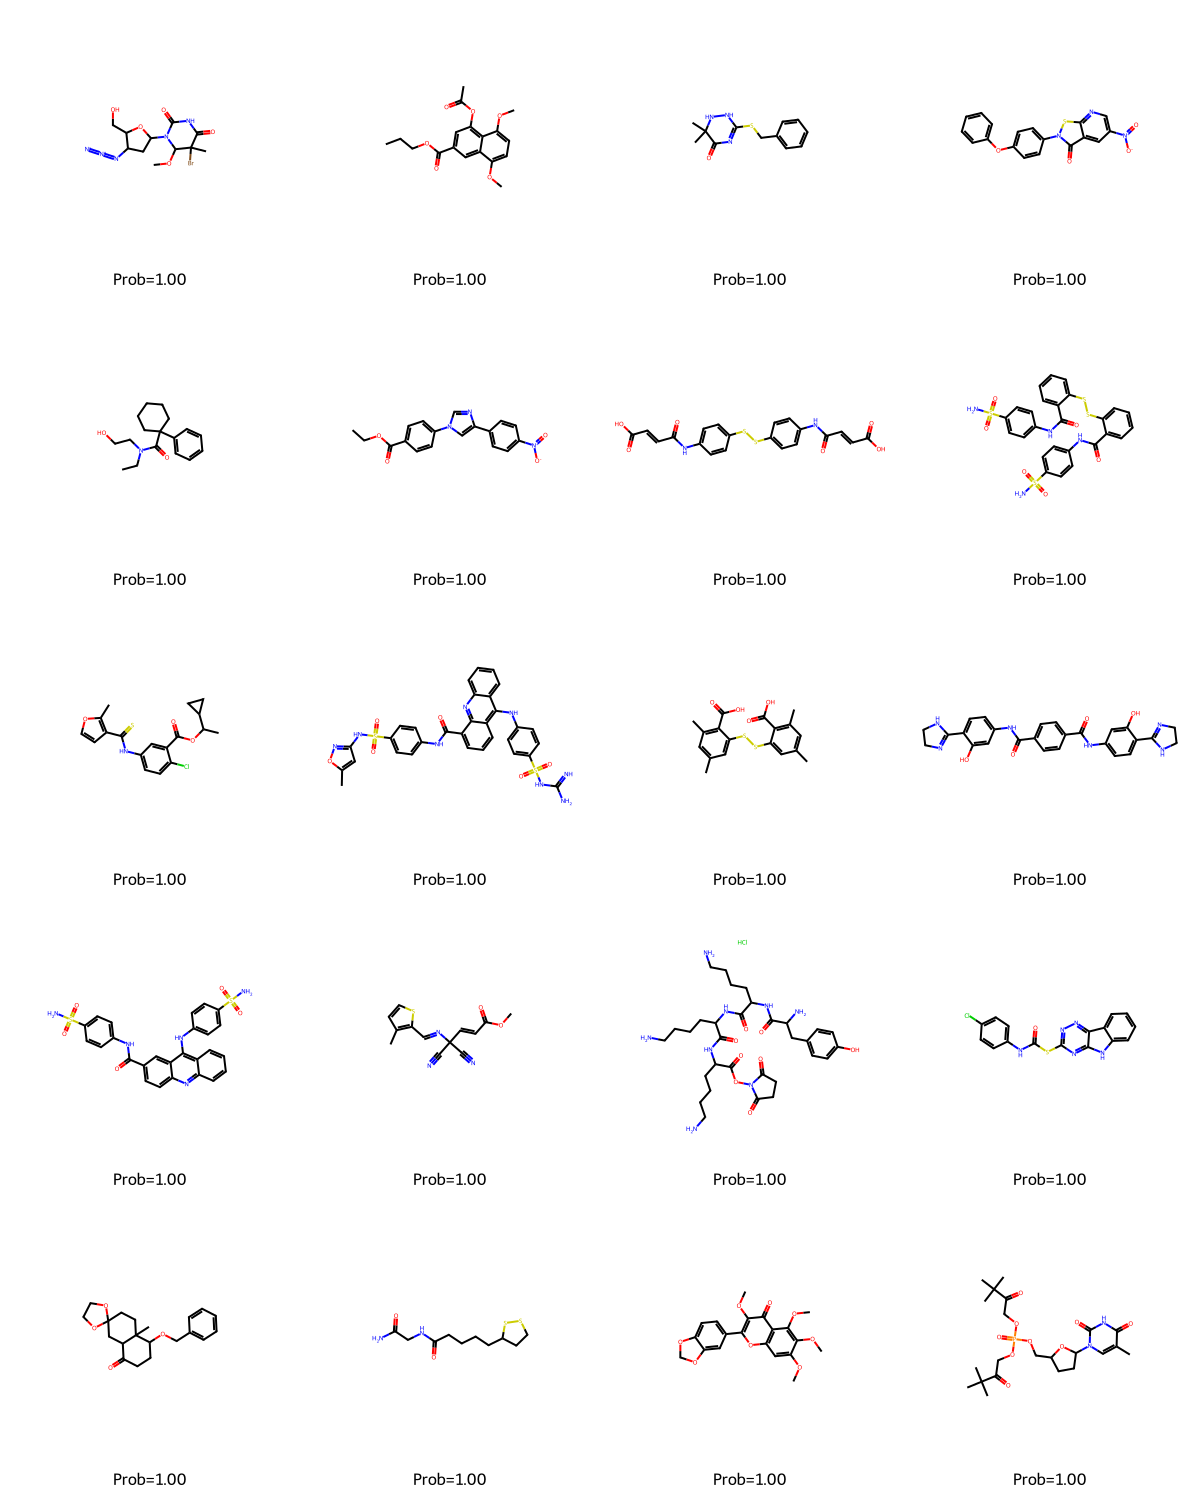

featurizer.pkl saved!

Models saved successfully! (model.pkl & lr_model.pkl)

Simulation finished.


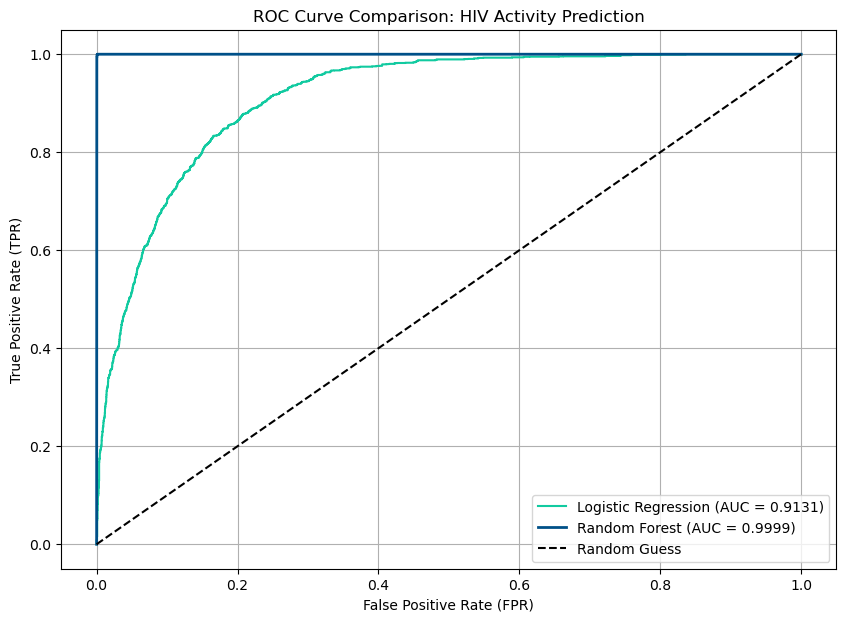

In [12]:
# Full final pipeline (balanced + visualization)
import deepchem as dc
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import warnings
from rdkit.Chem import Draw

# RDKit + image libs
import contextlib
import sys
import os
import urllib.request
try:
    import rdkit
    from rdkit import Chem
    from rdkit.Chem import Draw
except ImportError:
    print("RDKit not found. Please install it: pip install rdkit-pypi")

from sklearn.utils import resample
from io import BytesIO
from PIL import Image

# context manager to suppress RDKit stderr
@contextlib.contextmanager
def suppress_stderr():
    original_stderr = sys.stderr
    try:
        with open(os.devnull, 'w') as devnull:
            sys.stderr = devnull
            yield
    finally:
        sys.stderr = original_stderr

warnings.filterwarnings('ignore')
print("Starting the Drug Discovery ML Simulation (balanced pipeline)...")

# -----------------------
# 1. Download / load dataset
# -----------------------
with suppress_stderr():
    HIV_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/HIV.csv"
    try:
        script_dir = os.path.dirname(os.path.abspath(__file__))
    except NameError:
        script_dir = os.path.abspath('.')
    dataset_dir = os.path.join(script_dir, 'hiv_dataset')
    dataset_file = os.path.join(dataset_dir, "HIV.csv")
    os.makedirs(dataset_dir, exist_ok=True)
    if not os.path.exists(dataset_file):
        print(f"Downloading dataset to {dataset_file}...")
        urllib.request.urlretrieve(HIV_URL, dataset_file)
        print("Download complete.")

# Load using dataset_file (as you requested)
df = pd.read_csv(dataset_file)
print("Raw dataset loaded. Rows:", len(df))

# -----------------------
# 2. Pre-validate SMILES (remove invalid)
# -----------------------
print("Pre-validating SMILES with RDKit...")
all_smiles = df['smiles'].values
all_labels = df['HIV_active'].values

valid_smiles = []
valid_labels = []
with suppress_stderr():
    for i, s in enumerate(all_smiles):
        try:
            mol = Chem.MolFromSmiles(s)
        except Exception:
            mol = None
        if mol is not None:
            valid_smiles.append(s)
            valid_labels.append(all_labels[i])

print(f"Removed {len(all_smiles) - len(valid_smiles)} invalid SMILES entries.")
# at this point valid_smiles, valid_labels are lists

# -----------------------
# 3. BALANCE dataset by OVERSAMPLING (active -> match inactive)
# -----------------------
print("\nBalancing dataset using oversampling...")
temp_df = pd.DataFrame({
    "SMILES": valid_smiles,
    "HIV_active": valid_labels
})

active_df = temp_df[temp_df["HIV_active"] == 1]
inactive_df = temp_df[temp_df["HIV_active"] == 0]

print(f"Active count before oversampling: {len(active_df)}")
print(f"Inactive count before oversampling: {len(inactive_df)}")

# If there are zero actives (edge case), skip oversampling
if len(active_df) == 0:
    print("Warning: No active molecules found in validated data. Skipping oversampling.")
    balanced_df = temp_df.copy()
else:
    active_upsampled = resample(
        active_df,
        replace=True,
        n_samples=len(inactive_df),
        random_state=42
    )
    balanced_df = pd.concat([inactive_df, active_upsampled]).sample(frac=1, random_state=42)

print("Balanced dataset shape:", balanced_df.shape)
print(balanced_df["HIV_active"].value_counts())

# Replace arrays and create DeepChem dataset
smiles = balanced_df["SMILES"].values
labels = balanced_df["HIV_active"].values
dataset = dc.data.NumpyDataset(X=smiles, y=labels, ids=smiles)

# -----------------------
# 4. Split dataset (STRATIFIED SPLIT)
# -----------------------


print("\nSplitting dataset using STRATIFIED SPLIT...")

X_temp, X_test, y_temp, y_test = train_test_split(
    smiles, labels, test_size=0.1, random_state=42, stratify=labels
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.111, random_state=42, stratify=y_temp
)

# -----------------------
# PRINT SPLIT SIZES
# -----------------------
print("Train size:", len(X_train))
print("Validation size:", len(X_valid))
print("Test size:", len(X_test))

print("\nClass distribution:")
print("Train:", pd.Series(y_train).value_counts().to_dict())
print("Validation:", pd.Series(y_valid).value_counts().to_dict())
print("Test:", pd.Series(y_test).value_counts().to_dict())

# Save original SMILES BEFORE featurization
X_train_smiles = X_train.copy()
X_valid_smiles = X_valid.copy()
X_test_smiles  = X_test.copy()



# -----------------------
# 5. Featurization (Circular / Morgan fingerprint)
# -----------------------
print("\nFeaturizing (Circular fingerprints)... This may take some time.")
featurizer = dc.feat.CircularFingerprint(size=1024, radius=2)
feature_size = 1024

def robust_featurize(smiles_list, feature_size):
    features = []
    for s in smiles_list:
        try:
            feat = featurizer.featurize([s])
            if feat.size > 0:
                features.append(feat[0])
            else:
                features.append(np.zeros(feature_size, dtype=int))
        except Exception:
            features.append(np.zeros(feature_size, dtype=int))
    return np.array(features)

with suppress_stderr():
    X_train = robust_featurize(X_train, feature_size)
    X_valid = robust_featurize(X_valid, feature_size)
    X_test = robust_featurize(X_test, feature_size)

# labels already exist (y_train, y_valid, y_test)
y_train = np.array(y_train)
y_valid = np.array(y_valid)
y_test = np.array(y_test)

print(f"Featurization complete. Train:{len(X_train)} Test:{len(X_test)} Feature length:{X_train.shape[1]}")

# 6. Train models
# -----------------------
print("\nTraining Logistic Regression model...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

print("Training Random Forest model...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest training complete.")

# -----------------------
# 7. Evaluation on test set
# -----------------------
print("\n--- Model Evaluation (on Test Set) ---")
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

acc_lr = accuracy_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

acc_rf = accuracy_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("\nLogistic Regression:")
print(f"  Accuracy: {acc_lr:.4f}")
print(f"  ROC-AUC:  {roc_auc_lr:.4f}")

print("\nRandom Forest:")
print(f"  Accuracy: {acc_rf:.4f}")
print(f"  ROC-AUC:  {roc_auc_rf:.4f}")

print("\n--- Inference ---")
if roc_auc_rf > roc_auc_lr:
    print("Random Forest outperformed Logistic Regression, as expected.")
else:
    print("Logistic Regression performed comparably or better than Random Forest.")
print("This simulation shows how ML can screen and prioritize compounds for lab testing.")

# -----------------------
# 8. Save ROC plot
# -----------------------
print("\nGenerating ROC Curve plot...")
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(10, 7))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})', color='#11caa0')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.4f})', color='#005088', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison: HIV Activity Prediction')
plt.legend(loc='lower right')
plt.grid()
plt.savefig('hiv_ml_roc_curve.png')
print("ROC Curve plot saved as 'hiv_ml_roc_curve.png'")

#TOP MOLECULES

print("\n--- Identifying Top Predicted Active Molecules ---")
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

results_df = pd.DataFrame({
    "SMILES": X_test_smiles,     # <- FIXED
    "True_Label": y_test,
    "Predicted_Probability": test_probabilities
})

ranked_hits = results_df.sort_values(by="Predicted_Probability", ascending=False)
top_hits = ranked_hits.head(20)

print("\nTop 20 Predicted HIV-Active Molecules (virtual screening hits):")
print(top_hits)

top_hits.to_csv("top_predicted_hits.csv", index=False)
print("Saved top predicted molecules to 'top_predicted_hits.csv'")

# -----------------------
# 10. Visualize & save top molecules (robust across RDKit versions)
# -----------------------
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from PIL import Image
import numpy as np
from io import BytesIO

print("\nVisualizing Top 20 Predicted Molecules...")

top_smiles = list(top_hits["SMILES"])
mols = [Chem.MolFromSmiles(s) for s in top_smiles]
legends = [f"Prob={p:.2f}" for p in top_hits["Predicted_Probability"]]

# RDKit returns a PIL image directly in your version
img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(300, 300),
    legends=legends
)

# Show image in notebook
display(img)

import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("lr_model.pkl", "wb") as f:
    pickle.dump(lr_model, f)

with open("featurizer.pkl", "wb") as f:
    pickle.dump(featurizer, f)

print("featurizer.pkl saved!")

print("\nModels saved successfully! (model.pkl & lr_model.pkl)")

print("\nSimulation finished.")
